# 06 · Motor de simulación: métricas, sensibilidad y palancas

`pension_mc.simulate.simular(perfil, supuestos)` conecta los pasos 3 a 6 para un afiliado y devuelve la distribución de su resultado en una AFP y en Colpensiones. Todos los escenarios usan números aleatorios comunes, así que las diferencias entre ellos se deben al cambio de supuesto y no al ruido de la simulación.

Montos en pesos de 2026; mesadas en salarios mínimos (SMMLV) del año de retiro. La **mesada media total** promedia también los casos sin pensión (devolución de saldos), así que resume en un número la probabilidad de pensionarse y el monto.

In [1]:
import time
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pension_mc import regimes as G
from pension_mc.decumulation import factor_anualidad
from pension_mc.simulate import Perfil, Supuestos, simular, tornado
from pension_mc.config import parametros

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
BAJO, ALTO = "#2a78d6", "#e34948"            # par divergente
AZUL = {"150": "#b7d3f6", "250": "#86b6ef", "650": "#104281"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})
pct = lambda d=0: mtick.PercentFormatter(1, decimals=d)
SMMLV = parametros()["smmlv"]["valores"][2026]
N = 10_000

# Perfiles de referencia: 30 años, cotizan hoy, 250 semanas
MUJER_SUP = Perfil(edad=30, sexo="Mujer", educacion="Superior", salario=2 * SMMLV, semanas=250, cotiza_hoy=True)
HOMBRE_MED = Perfil(edad=30, sexo="Hombre", educacion="Media", salario=SMMLV, semanas=250, cotiza_hoy=True)
METRICAS = {"afp_p_pension": "P(pensión) en la AFP", "afp_p_capital_suficiente": "P(capital suficiente)",
            "afp_mesada_p50": "Mesada mediana si se pensiona (SMMLV)", "afp_mesada_media_total": "Mesada media total (SMMLV)",
            "afp_reemplazo_p50": "Reemplazo mediano si se pensiona", "semanas_p50": "Semanas (mediana)",
            "afp_saldo_p50_millones": "Saldo mediano (millones)", "afp_costo_garantia_medio_millones": "Costo medio de la garantía (millones)",
            "colpensiones_p_pension": "P(pensión) en Colpensiones", "colpensiones_mesada_p50": "Mesada mediana Colpensiones (SMMLV)"}

## 1. Un perfil de punta a punta

In [2]:
t0 = time.time()
r = simular(MUJER_SUP, n_sims=N, guardar_saldo=True)
print(f"{N:,} simulaciones en {time.time() - t0:.1f} s; retiro a los {r.edad_retiro:.0f} años en {r.anio_retiro}")
res = r.resumen()
res.rename(METRICAS).loc[list(METRICAS.values())].to_frame("Mujer, 30 años, superior, 2 SMMLV, 250 semanas").style.format("{:.2f}")

10,000 simulaciones en 1.6 s; retiro a los 57 años en 2053


,"Mujer, 30 años, superior, 2 SMMLV, 250 semanas"
P(pensión) en la AFP,0.93
P(capital suficiente),0.14
Mesada mediana si se pensiona (SMMLV),1.00
Mesada media total (SMMLV),1.00
Reemplazo mediano si se pensiona,0.46
Semanas (mediana),1638.57
Saldo mediano (millones),351.61
Costo medio de la garantía (millones),181.16
P(pensión) en Colpensiones,0.93
Mesada mediana Colpensiones (SMMLV),1.85


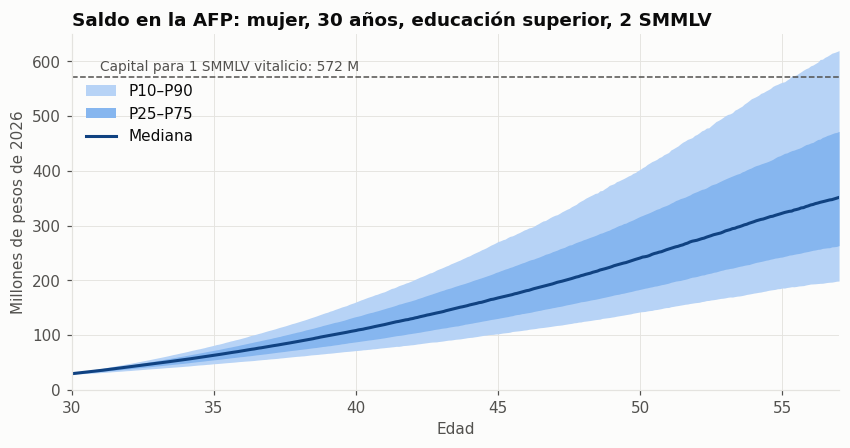

In [3]:
edades = MUJER_SUP.edad + np.arange(1, r.saldo.shape[1] + 1) / 12
q = np.percentile(r.saldo, [10, 25, 50, 75, 90], axis=0) / 1e6
capital = r.smmlv_retiro * factor_anualidad(57.0, "Mujer", crecimiento=parametros()["supuestos"]["crecimiento_real_smmlv"]) / 1e6
fig, ax = plt.subplots()
ax.fill_between(edades, q[0], q[4], color=AZUL["150"], lw=0, label="P10–P90")
ax.fill_between(edades, q[1], q[3], color=AZUL["250"], lw=0, label="P25–P75")
ax.plot(edades, q[2], color=AZUL["650"], label="Mediana")
ax.axhline(capital, color=INK2, lw=1, ls="--")
ax.annotate(f"Capital para 1 SMMLV vitalicio: {capital:,.0f} M", (31, capital), xytext=(0, 4), textcoords="offset points",
            color=INK2, fontsize=9)
ax.set_xlabel("Edad")
ax.set_ylabel("Millones de pesos de 2026")
ax.set_title("Saldo en la AFP: mujer, 30 años, educación superior, 2 SMMLV")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9))
ax.set_xlim(30, 57)
plt.show()

Incluso en el percentil 90, el saldo a los 57 años apenas alcanza el capital necesario para financiar 1 SMMLV de por vida, que crece con el SMMLV. Por eso la mayoría de los escenarios termina en la garantía de pensión mínima. Es el caso típico de una mujer de ingreso medio en las AFP: cotiza lo suficiente para pensionarse, pero no lo suficiente para financiar más que el mínimo a los 57 años.

## 2. Convergencia de Monte Carlo

In [4]:
filas = []
for n in (1_000, 5_000, 20_000):
    v = pd.DataFrame([simular(MUJER_SUP, Supuestos(seed=s), n_sims=n).resumen() for s in range(20)])
    p = v.afp_p_pension.mean()
    filas.append({"simulaciones": n, "P(pensión) media": p, "desv. entre 20 semillas": v.afp_p_pension.std(),
                  "error binomial teórico": np.sqrt(p * (1 - p) / n),
                  "mesada media total": v.afp_mesada_media_total.mean(), "desv. entre semillas (mesada)": v.afp_mesada_media_total.std()})
pd.DataFrame(filas).set_index("simulaciones").style.format("{:.4f}")

,P(pensión) media,desv. entre 20 semillas,error binomial teórico,mesada media total,desv. entre semillas (mesada)
simulaciones,,,,,
1000,0.9324,0.0060,0.0079,1.0003,0.0118
5000,0.9310,0.0032,0.0036,0.9987,0.0049
20000,0.9319,0.0019,0.0018,0.9990,0.0029


La desviación entre semillas coincide con el error binomial teórico y cae como 1/√n: con 10.000 simulaciones, P(pensión) tiene un error de ~0,5 puntos. Las comparaciones entre escenarios son todavía más precisas, porque usan los mismos números aleatorios.

*Nota de implementación:* en una primera versión, cada componente usaba la semilla `seed + k`, así que semillas consecutivas compartían flujos aleatorios entre componentes y las corridas "independientes" quedaban correlacionadas (la desviación no caía con n). Ahora las semillas de los componentes se derivan con `numpy.random.SeedSequence`.

## 3. Sensibilidad: ¿qué supuestos mueven el resultado?

Cada supuesto se mueve a un valor bajo y uno alto, con los demás en su valor base:

| Supuesto | Bajo | Base | Alto |
|---|---|---|---|
| Rentabilidad real de los fondos | −1 punto | histórica (Protección 2016–2026) | +1 punto |
| Tasa técnica real | 3 % | 4 % | 5 % |
| Crecimiento real del SMMLV | 0 % | 1 % | 2,4 % (parámetro oficial) |
| Crecimiento real de los salarios | 0 % | 1 % | 2 % |
| Edad a la que se consolida la situación laboral | 25 años | 30 años (estimada) | 35 años |

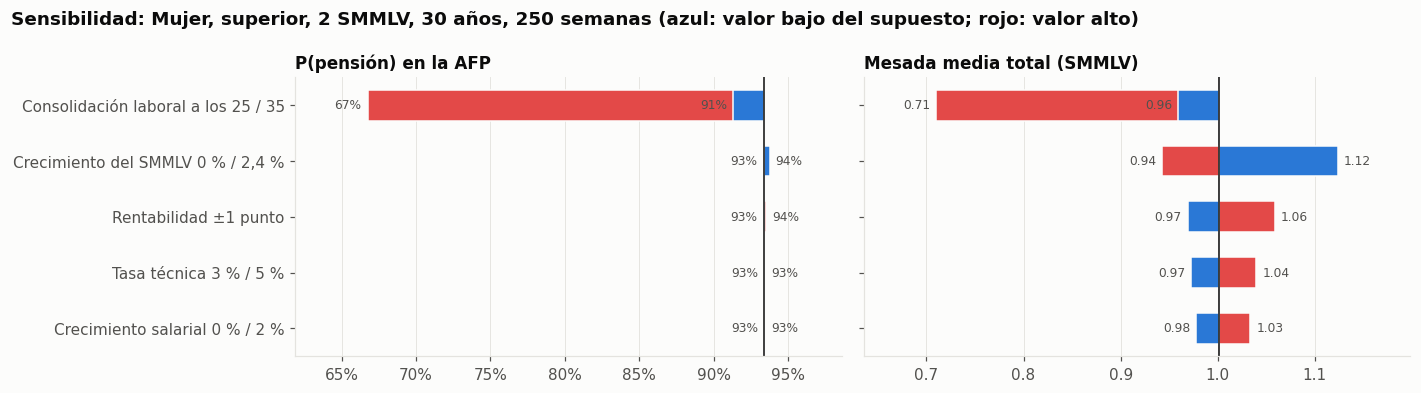

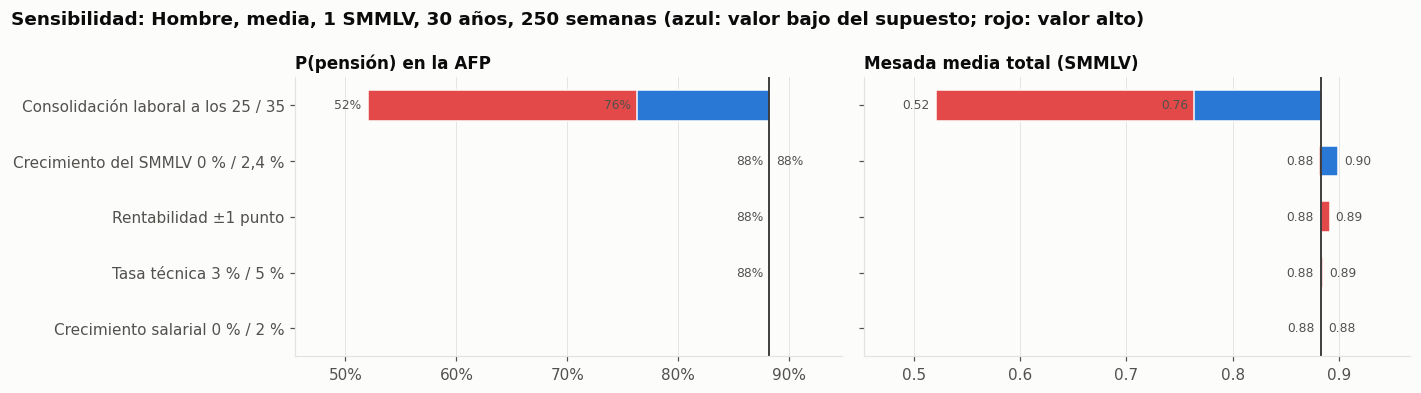

In [5]:
VARIACIONES = {
    "Rentabilidad ±1 punto": ({"ajuste_rentabilidad": -0.01}, {"ajuste_rentabilidad": 0.01}),
    "Tasa técnica 3 % / 5 %": ({"tasa_tecnica": 0.03}, {"tasa_tecnica": 0.05}),
    "Crecimiento del SMMLV 0 % / 2,4 %": ({"crecimiento_smmlv": 0.0}, {"crecimiento_smmlv": 0.0239}),
    "Crecimiento salarial 0 % / 2 %": ({"crecimiento_salarios": 0.0}, {"crecimiento_salarios": 0.02}),
    "Consolidación laboral a los 25 / 35": ({"cotizacion": "η se consolida a los 25"}, {"cotizacion": "η se consolida a los 35"}),
}
tornados = {}
for nombre, pf in [("Mujer, superior, 2 SMMLV", MUJER_SUP), ("Hombre, media, 1 SMMLV", HOMBRE_MED)]:
    tornados[nombre] = tornado(pf, VARIACIONES, metricas=("afp_p_pension", "afp_p_capital_suficiente", "afp_mesada_media_total",
                                                          "colpensiones_p_pension"), n_sims=N)

def grafico_tornado(ax, t, metrica, titulo, formato):
    d = t[t.metrica == metrica].sort_values("rango")
    base = d.base.iloc[0]
    y = np.arange(len(d))
    for yi, (_, f) in enumerate(d.iterrows()):
        # la barra más larga primero, para que la corta quede visible encima
        for v, col in sorted(((f.bajo, BAJO), (f.alto, ALTO)), key=lambda x: -abs(x[0] - base)):
            ax.barh(yi, v - base, left=base, color=col, height=0.55, edgecolor=SURFACE, linewidth=1)
        for v in {f.bajo, f.alto}:
            if abs(v - base) > 1e-9:
                ax.annotate(formato(v), (v, yi), xytext=(4 if v > base else -4, 0), textcoords="offset points",
                            ha="left" if v > base else "right", va="center", color=INK2, fontsize=8)
    extremos = np.r_[d.bajo, d.alto, base]
    margen = 0.18 * (extremos.max() - extremos.min()) + 1e-6
    ax.set_xlim(extremos.min() - margen, extremos.max() + margen)
    ax.axvline(base, color=INK, lw=1)
    ax.set_yticks(y, d.supuesto)
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis="y", visible=False)

for nombre, t in tornados.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
    grafico_tornado(axes[0], t, "afp_p_pension", "P(pensión) en la AFP", lambda v: f"{v:.0%}")
    grafico_tornado(axes[1], t, "afp_mesada_media_total", "Mesada media total (SMMLV)", lambda v: f"{v:.2f}")
    axes[0].xaxis.set_major_formatter(pct())
    fig.suptitle(f"Sensibilidad: {nombre}, 30 años, 250 semanas (azul: valor bajo del supuesto; rojo: valor alto)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()
pd.concat(tornados, names=["perfil"]).reset_index(level=0).query("metrica != 'colpensiones_p_pension'").set_index(
    ["perfil", "metrica", "supuesto"]).style.format("{:.3f}")

**Lectura** (ver los valores en la tabla):

- **La probabilidad de pensionarse depende casi solo de la cotización.** Rentabilidad, tasa técnica y crecimiento salarial la mueven menos de medio punto: para estos perfiles el destino es garantía mínima o devolución de saldos, y lo decide el número de semanas.
- **Para alguien de 30 años, la predicción individual depende de la edad a la que se consolida la situación laboral.** Con consolidación a los 30 (base), la mujer que hoy cotiza y tiene 250 semanas se pensiona en el 93 % de los casos; con consolidación a los 35, en el 67 %. Para el hombre: 88 % frente a 52 %. A los 30 años, la historia es muy informativa solo si ya pasó la edad de consolidación. El agregado poblacional es robusto a este supuesto (notebook 04), pero el simulador debe comunicar esta incertidumbre a los usuarios cercanos a esa edad.
- **El crecimiento real del SMMLV es el supuesto económico que más pesa en la mesada.** Con 0 % de crecimiento, el 42 % de la mujer de referencia financia más que el mínimo; con el 2,4 % del parámetro oficial, solo el 1 %. A la vez, quien termina en la garantía recibe un mínimo más alto. Por eso la mesada media cae de 1,12 a 0,94 SMMLV.
- **La rentabilidad y la tasa técnica importan solo cerca del umbral de capital suficiente.** ±1 punto de rentabilidad mueve la probabilidad de financiar más que el mínimo del 7 % al 23 % en la mujer de referencia. Para el hombre de salario mínimo casi no cambia nada.

## 4. Palancas del afiliado

Para la mujer de referencia (30 años, superior, 2 SMMLV): ¿qué decisiones cambian su pensión?

In [6]:
filas = []
escenarios = {
    "Base (multifondos por defecto, retiro a los 57)": (MUJER_SUP, Supuestos()),
    "Aporte voluntario 2 % del salario": (replace(MUJER_SUP, aporte_voluntario_pct=0.02), Supuestos()),
    "Aporte voluntario 5 %": (replace(MUJER_SUP, aporte_voluntario_pct=0.05), Supuestos()),
    "Aporte voluntario 10 %": (replace(MUJER_SUP, aporte_voluntario_pct=0.10), Supuestos()),
    "Retiro a los 60 (sigue cotizando como a los 55)": (replace(MUJER_SUP, edad_retiro=60), Supuestos(congelar_cotizacion_desde=55)),
    "Retiro a los 62": (replace(MUJER_SUP, edad_retiro=62), Supuestos(congelar_cotizacion_desde=55)),
    "Retiro a los 62 + aporte voluntario 5 %": (replace(MUJER_SUP, edad_retiro=62, aporte_voluntario_pct=0.05), Supuestos(congelar_cotizacion_desde=55)),
    "Todo en el fondo conservador": (replace(MUJER_SUP, fondo="conservador"), Supuestos()),
    "Todo en el fondo moderado": (replace(MUJER_SUP, fondo="moderado"), Supuestos()),
    "Todo en el fondo de mayor riesgo": (replace(MUJER_SUP, fondo="mayor_riesgo"), Supuestos()),
}
res = {k: simular(pf, sp, n_sims=N) for k, (pf, sp) in escenarios.items()}
for k, rr in res.items():
    s = rr.resumen()
    ganancia = rr.afp.mesada[rr.afp.estado == "capital_suficiente"] / rr.smmlv_retiro
    filas.append({"escenario": k, "P(pensión)": s.afp_p_pension, "P(capital suficiente)": s.afp_p_capital_suficiente,
                  "mesada media total": s.afp_mesada_media_total, "mesada P90": s.afp_mesada_p90,
                  "saldo mediano (M)": s.afp_saldo_p50_millones, "costo garantía (M)": s.afp_costo_garantia_medio_millones})
palancas = pd.DataFrame(filas).set_index("escenario")
palancas.style.format({"P(pensión)": "{:.0%}", "P(capital suficiente)": "{:.0%}", "mesada media total": "{:.2f}",
                       "mesada P90": "{:.2f}", "saldo mediano (M)": "{:,.0f}", "costo garantía (M)": "{:,.0f}"})

,P(pensión),P(capital suficiente),mesada media total,mesada P90,saldo mediano (M),costo garantía (M)
escenario,,,,,,
"Base (multifondos por defecto, retiro a los 57)",93%,14%,1.00,1.25,352,181
Aporte voluntario 2 % del salario,93%,21%,1.05,1.44,398,147
Aporte voluntario 5 %,94%,33%,1.14,1.71,468,106
Aporte voluntario 10 %,94%,52%,1.33,2.16,584,60
Retiro a los 60 (sigue cotizando como a los 55),94%,24%,1.07,1.49,400,136
Retiro a los 62,94%,31%,1.13,1.66,432,107
Retiro a los 62 + aporte voluntario 5 %,94%,56%,1.38,2.27,578,50
Todo en el fondo conservador,93%,6%,0.96,1.00,281,241
Todo en el fondo moderado,93%,14%,1.00,1.26,356,179


In [7]:
# La "trampa de la pensión mínima": ¿cuánto de cada peso de ahorro voluntario vuelve en mesada?
base = res["Base (multifondos por defecto, retiro a los 57)"]
filas = []
for k in ["Aporte voluntario 2 % del salario", "Aporte voluntario 5 %", "Aporte voluntario 10 %"]:
    rr = res[k]
    extra_saldo = rr.afp.saldo - base.afp.saldo                    # mismos números aleatorios: comparación por simulación
    f = factor_anualidad(57.0, "Mujer")
    extra_mesada = rr.afp.mesada - base.afp.mesada
    valor_extra = extra_mesada * f                                 # valor presente de la mesada adicional
    filas.append({"escenario": k, "ahorro adicional medio (M)": extra_saldo.mean() / 1e6,
                  "valor de la mesada adicional (M)": valor_extra.mean() / 1e6,
                  "rendimiento del ahorro voluntario": valor_extra.sum() / extra_saldo.sum(),
                  "simulaciones en que no cambia la mesada": (extra_mesada.abs() < 1).mean()})
pd.DataFrame(filas).set_index("escenario").style.format({"ahorro adicional medio (M)": "{:,.0f}", "valor de la mesada adicional (M)": "{:,.0f}",
                                                         "rendimiento del ahorro voluntario": "{:.0%}", "simulaciones en que no cambia la mesada": "{:.0%}"})

,ahorro adicional medio (M),valor de la mesada adicional (M),rendimiento del ahorro voluntario,simulaciones en que no cambia la mesada
escenario,,,,
Aporte voluntario 2 % del salario,53,23,43%,79%
Aporte voluntario 5 %,132,68,52%,67%
Aporte voluntario 10 %,264,166,63%,48%


**La trampa de la pensión mínima.** Si sin el ahorro voluntario la persona iba a recibir la garantía mínima, ahorrar más solo reduce lo que paga el Estado, salvo que el ahorro adicional la lleve por encima del umbral de capital suficiente. Con un aporte del 2 % del salario, la mesada no cambia en el 79 % de las simulaciones, y solo el 43 % del valor ahorrado vuelve como valor presente de mesada. Con el 10 %, vuelve el 63 %. El resto sustituye subsidio estatal.

**Otras palancas:**
- **Edad de retiro.** Pensionarse a los 62 en vez de a los 57, siguiendo cotizando, tiene un efecto parecido a un aporte voluntario del 5 % durante 27 años: la probabilidad de financiar más que el mínimo sube del 14 % al 31 % (33 % con el aporte). Combinadas, llega al 56 %. *(La mesada media no descuenta los 5 años menos de pensión.)*
- **Fondo.** Todo en mayor riesgo frente a todo en conservador: 20 % vs. 6 % de probabilidad de financiar más que el mínimo. La trayectoria por defecto da el mismo resultado que el fondo moderado.

**Implicación de negocio:** para afiliados de ingreso medio que probablemente terminen en la garantía mínima, un aporte voluntario pequeño a la cuenta obligatoria casi no cambia su pensión. La asesoría debería partir de la distancia al umbral de capital suficiente, que este simulador calcula, y considerar la edad de retiro y vehículos voluntarios con liquidez antes que aportes marginales a la cuenta obligatoria.

## 5. ¿Cuánto cuesta una laguna de 5 años?

In [8]:
filas = []
for nombre, pf in [("Mujer, superior, 2 SMMLV", replace(MUJER_SUP, edad=25, semanas=50)),
                   ("Hombre, media, 1 SMMLV", replace(HOMBRE_MED, edad=25, semanas=50))]:
    for lag, etiqueta in [(None, "sin laguna"), ((25, 30), "laguna 25–30"), ((40, 45), "laguna 40–45")]:
        s = simular(replace(pf, laguna=lag), n_sims=N).resumen()
        filas.append({"perfil": nombre, "escenario": etiqueta, "semanas (mediana)": s.semanas_p50,
                      "P(pensión) AFP": s.afp_p_pension, "mesada media total": s.afp_mesada_media_total,
                      "P(pensión) Colpensiones": s.colpensiones_p_pension})
lag = pd.DataFrame(filas).set_index(["perfil", "escenario"])
lag.style.format({"semanas (mediana)": "{:,.0f}", "P(pensión) AFP": "{:.0%}", "mesada media total": "{:.2f}", "P(pensión) Colpensiones": "{:.0%}"})

Cinco años sin cotizar cuestan 3–5 puntos de probabilidad de pensionarse y unas 150–260 semanas en la mediana. La cadena de cotización continúa desde "no cotiza", así que la laguna también afecta lo que viene después. A los 40–45 años el costo en semanas es algo mayor que a los 25–30: después de los 30 la situación laboral está consolidada, y quien deja de cotizar tiene más difícil volver.

## 6. Brecha de género

In [9]:
HOMBRE_SUP = replace(MUJER_SUP, sexo="Hombre")
escenarios = {
    "Mujer, retiro a los 57": (MUJER_SUP, Supuestos()),
    "Mujer, retiro a los 62": (replace(MUJER_SUP, edad_retiro=62), Supuestos(congelar_cotizacion_desde=55)),
    "Hombre, retiro a los 62": (HOMBRE_SUP, Supuestos()),
}
filas = []
for k, (pf, sp) in escenarios.items():
    s = simular(pf, sp, n_sims=N).resumen()
    filas.append({"escenario": k, "P(pensión) AFP": s.afp_p_pension, "P(capital suficiente)": s.afp_p_capital_suficiente,
                  "mesada media total": s.afp_mesada_media_total, "mesada P90": s.afp_mesada_p90,
                  "P(pensión) Colpensiones": s.colpensiones_p_pension, "mesada Colpensiones (mediana)": s.colpensiones_mesada_p50})
pd.DataFrame(filas).set_index("escenario").style.format({c: "{:.0%}" if c.startswith("P(") else "{:.2f}" for c in filas[0] if c != "escenario"})

,P(pensión) AFP,P(capital suficiente),mesada media total,mesada P90,P(pensión) Colpensiones,mesada Colpensiones (mediana)
escenario,,,,,,
"Mujer, retiro a los 57",93%,14%,1.00,1.25,93%,1.85
"Mujer, retiro a los 62",94%,31%,1.13,1.66,94%,1.82
"Hombre, retiro a los 62",96%,61%,1.43,2.32,93%,2.20


Misma educación, mismo salario y misma historia. Las diferencias vienen de tres fuentes: las mujeres cotizan menos meses (modelo de cotización), se pensionan 5 años antes y viven más (RV08). El hombre financia más que el mínimo en el 61 % de los casos; la mujer, en el 14 % si se retira a los 57 y en el 31 % si se retira a los 62. Retrasar el retiro cierra cerca de un tercio de la brecha; el resto viene de la menor cotización y la mayor esperanza de vida.

## 7. ¿A quién le conviene cada régimen? Gradiente por nivel de ingreso

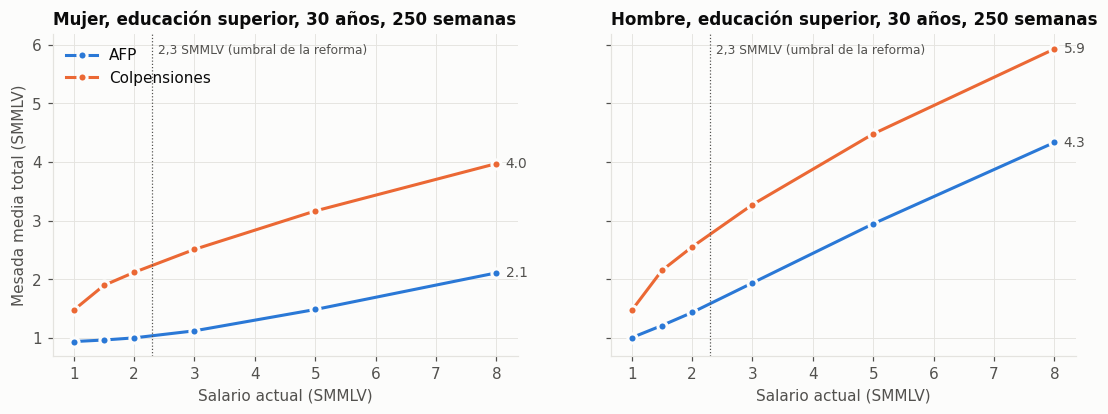

In [10]:
filas = []
for educ, sexo in [("Superior", "Mujer"), ("Superior", "Hombre")]:
    for x in (1, 1.5, 2, 3, 5, 8):
        pf = Perfil(edad=30, sexo=sexo, educacion=educ, salario=x * SMMLV, semanas=250, cotiza_hoy=True)
        s = simular(pf, n_sims=N).resumen()
        filas.append({"sexo": sexo, "salario (SMMLV)": x, "AFP": s.afp_mesada_media_total, "Colpensiones": s.colpensiones_mesada_media_total,
                      "AFP P(capital suficiente)": s.afp_p_capital_suficiente, "reemplazo AFP": s.afp_reemplazo_p50,
                      "reemplazo Colpensiones": s.colpensiones_reemplazo_p50})
grad = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, sexo in zip(axes, ["Mujer", "Hombre"]):
    g = grad[grad.sexo == sexo]
    for i, col in enumerate(["AFP", "Colpensiones"]):
        ax.plot(g["salario (SMMLV)"], g[col], color=SERIES[i], marker="o", ms=6, mec=SURFACE, mew=2, label=col)
        ax.annotate(f"{g[col].iloc[-1]:.1f}", (g["salario (SMMLV)"].iloc[-1], g[col].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK2, fontsize=9)
    ax.axvline(2.3, color=INK2, lw=0.8, ls=":")
    ax.annotate("2,3 SMMLV (umbral de la reforma)", (2.3, 0.97), xycoords=ax.get_xaxis_transform(), xytext=(4, 0),
                textcoords="offset points", va="top", color=INK2, fontsize=8)
    ax.set_title(f"{sexo}, educación superior, 30 años, 250 semanas", fontsize=11)
    ax.set_xlabel("Salario actual (SMMLV)")
axes[0].set_ylabel("Mesada media total (SMMLV)")
axes[0].legend(loc="upper left")
plt.show()
grad.set_index(["sexo", "salario (SMMLV)"]).style.format("{:.2f}")

- **Colpensiones paga más que la AFP en todos los niveles de ingreso de estos perfiles.** Es el subsidio implícito del régimen de prima media, financiado por el presupuesto público y por las cotizaciones de los afiliados activos.
- **La brecha es mucho mayor para las mujeres.** A 8 SMMLV, Colpensiones paga 1,9 veces lo de la AFP a la mujer (4,0 vs. 2,1) y 1,4 veces al hombre (5,9 vs. 4,3). La regla del art. 34 no depende de la edad ni de la esperanza de vida; la cuenta individual, sí.
- Aun quien hoy gana 1 SMMLV con educación superior recibe ~50 % más en Colpensiones, porque su salario crece con la carrera y el IBL refleja los últimos 10 años.
- La reforma pensional (Ley 2381 de 2024) lleva a Colpensiones la cotización sobre los primeros 2,3 SMMLV de todos los afiliados (línea punteada).

## Hallazgos

1. **El motor es rápido y preciso.** 10.000 vidas laborales en ~2 segundos, con un error de Monte Carlo de ~0,5 puntos en las probabilidades (coincide con el error binomial teórico). Las comparaciones entre escenarios usan números aleatorios comunes.
2. **Lo que decide si alguien se pensiona son las semanas, no los mercados.** Rentabilidad, tasa técnica y crecimiento salarial mueven la probabilidad de pensionarse menos de medio punto.
3. **La predicción individual cerca de los 30 años es incierta.** Depende de si la situación laboral ya se consolidó: para la mujer de referencia, 93 % de probabilidad de pensionarse si se consolida a los 30 y 67 % si se consolida a los 35. El agregado poblacional sí es robusto (notebook 04).
4. **El crecimiento real del salario mínimo es el supuesto económico clave.** Determina el capital necesario para la pensión mínima: con 0 % de crecimiento, el 42 % de la mujer de referencia financia más que el mínimo; con el 2,4 % del parámetro oficial, el 1 %.
5. **La trampa de la pensión mínima:** con un aporte voluntario del 2 % del salario, la mesada no cambia en el 79 % de las simulaciones y solo vuelve el 43 % del valor ahorrado; el resto reemplaza subsidio estatal.
6. **Edad de retiro y fondo:** pensionarse a los 62 en vez de a los 57 equivale aproximadamente a ahorrar un 5 % adicional del salario durante 27 años. El fondo de mayor riesgo triplica, frente al conservador, la probabilidad de financiar más que el mínimo (20 % vs. 6 %).
7. **Brecha de género:** con la misma carrera, el hombre financia más que el mínimo en el 61 % de los casos y la mujer en el 14 % (31 % si se retira a los 62).
8. **Colpensiones paga más que la AFP en todos los niveles de ingreso, sobre todo a las mujeres** (hasta 1,9 veces a 8 SMMLV), porque su fórmula no depende de la esperanza de vida.

**Pendiente para los siguientes pasos:** escenario de la reforma pensional, validación externa contra simuladores oficiales (paso 8) y la app (paso 9).